# CareerCompass — Career Matcher (Supervised Learning on O*NET 31.0)

**Goal.** Given a student's profile expressed in O*NET terms (skills, knowledge, interests, preparation level), predict the
*career family* they fit and rank matching *occupations*. The ranked careers feed the CareerCompass roadmap agent
(courses → skills → career).

**Pipeline.** `download.py` → `features.py` (75-feature occupation matrix) → `train.py` (simulate students, train 5 models,
evaluate, export) → `career-model.json` used for inference in the web app.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "ml" / "src"))
occ = pd.read_csv(ROOT / "data/processed/occupations.csv", index_col="code", dtype={"family_code": str})
meta = json.loads((ROOT / "data/processed/feature_meta.json").read_text())
features = [m["id"] for m in meta]
print(f"{len(occ)} occupations × {len(features)} features, {occ['family'].nunique()} career families")
pd.Series([m["group"] for m in meta]).value_counts()

910 occupations × 75 features, 22 career families


Knowledge             33
Transferable skill    25
Essential skill       10
Interest               6
Preparation            1
Name: count, dtype: int64

## 1. The data
Each occupation is a vector in [0, 1]: importance of 10 essential skills, 25 transferable skills, 33 knowledge areas (1–5 scale), 6 RIASEC interest scores (1–7) and the job zone (1–5).

In [2]:
occ[["title", "family"] + features[:4] + ["ri:Investigative", "jz:zone"]].head(8).round(2)

,title,family,es:2.A.1.a,es:2.A.1.b,es:2.A.1.c,es:2.A.1.d,ri:Investigative,jz:zone
code,,,,,,,,
11-1011.00,Chief Executives,Management,0.78,0.75,0.78,0.81,0.34,1.00
11-1011.03,Chief Sustainability Officers,Management,0.75,0.75,0.78,0.75,0.63,1.00
11-1021.00,General and Operations Managers,Management,0.75,0.75,0.62,0.75,0.23,0.75
11-2011.00,Advertising and Promotions Managers,Management,0.69,0.78,0.69,0.78,0.12,0.75
11-2021.00,Marketing Managers,Management,0.72,0.78,0.56,0.75,0.32,0.75
11-2022.00,Sales Managers,Management,0.72,0.75,0.66,0.75,0.11,0.75
11-2032.00,Public Relations Managers,Management,0.78,0.78,0.75,0.81,0.22,0.75
11-2033.00,Fundraising Managers,Management,0.72,0.75,0.72,0.78,0.24,0.75


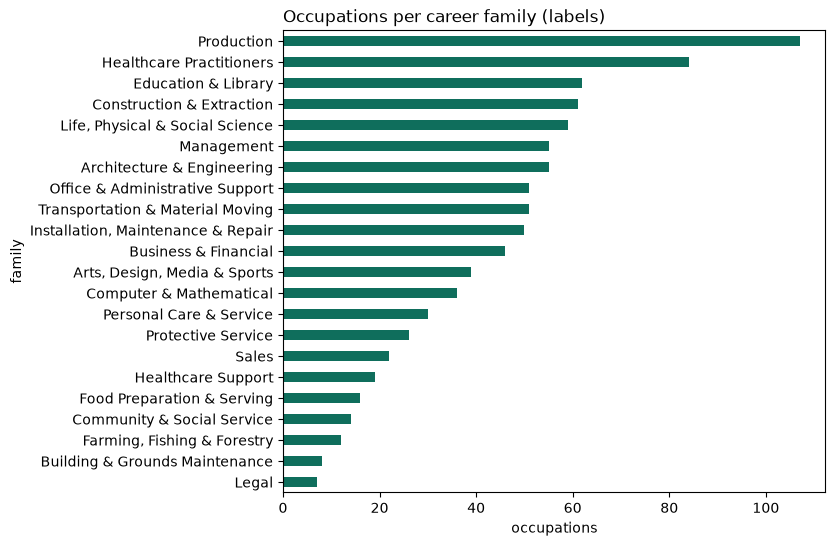

In [3]:
ax = occ["family"].value_counts().plot.barh(figsize=(7, 6), color="#0f6e5c")
ax.invert_yaxis(); ax.set_xlabel("occupations"); ax.set_title("Occupations per career family (labels)", loc="left");

## 2. Simulating students
O*NET gives one profile per occupation, which is not enough to learn a mapping from *noisy, incomplete student self-descriptions*.
For each occupation we draw noisy copies: Gaussian noise with a random strength σ ∈ [0.04, 0.22] and a random 0–35 % of features
hidden (replaced by the population mean, exactly as the app does for unknown fields).

In [4]:
from train import simulate_students
X = occ[features].to_numpy(float)
S, idx, sigma = simulate_students(X, 3, np.random.default_rng(0))
example = pd.DataFrame([X[idx[0]], S[0], S[1], S[2]], columns=features, index=["O*NET profile", "student 1", "student 2", "student 3"])
print("Occupation:", occ.index[idx[0]], occ.iloc[idx[0]]["title"])
example[features[:6]].round(2)

Occupation: 11-1011.00 Chief Executives


,es:2.A.1.a,es:2.A.1.b,es:2.A.1.c,es:2.A.1.d,es:2.A.1.e,es:2.A.1.f
O*NET profile,0.78,0.75,0.78,0.81,0.56,0.16
student 1,0.62,0.65,0.71,0.70,0.47,0.21
student 2,0.81,0.70,0.55,0.63,0.57,0.13
student 3,0.84,0.74,0.70,0.83,0.65,0.08


## 3. Results
Full training (`python ml/src/train.py`, ~2 minutes) writes `ml/reports/metrics.json` and figures. Loaded here:

In [5]:
m = json.loads((ROOT / "ml/reports/metrics.json").read_text())
rows = [{"model": k, "seen acc": v["accuracy"], "seen macro-F1": v["macro_f1"], "seen top-3": v["top3_accuracy"],
         "unseen acc": m["B_unseen_occupations"][k]["accuracy"], "unseen top-3": m["B_unseen_occupations"][k]["top3_accuracy"]}
        for k, v in m["A_stratified"].items()]
pd.DataFrame(rows).set_index("model").round(3)

,seen acc,seen macro-F1,seen top-3,unseen acc,unseen top-3
model,,,,,
Logistic Regression,0.709,0.674,0.928,0.609,0.873
k-Nearest Neighbours,0.906,0.898,0.985,0.580,0.826
Random Forest,0.783,0.751,0.960,0.606,0.867
Linear SVM,0.702,0.658,0.913,0.601,0.852
MLP (128-64),0.834,0.813,0.973,0.596,0.856


**Reading the table.** *Seen* = test samples come from occupations also present in training (stratified split).
*Unseen* = whole occupations are held out (group split) — the honest test of generalisation. k-NN is best on seen occupations because
it memorises near-duplicate neighbours, but it drops the most on unseen ones. **Logistic regression generalises best**, is
interpretable and tiny to export, so it is the deployed family classifier.

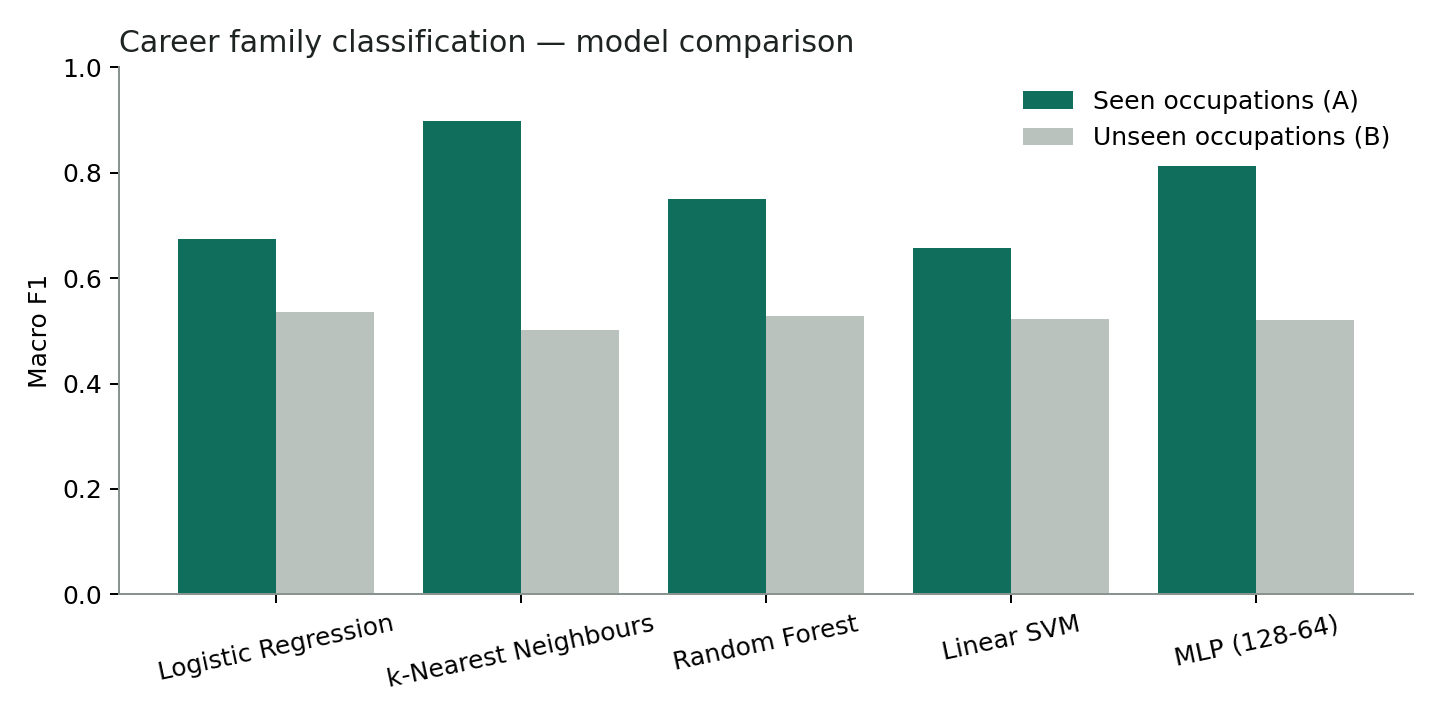

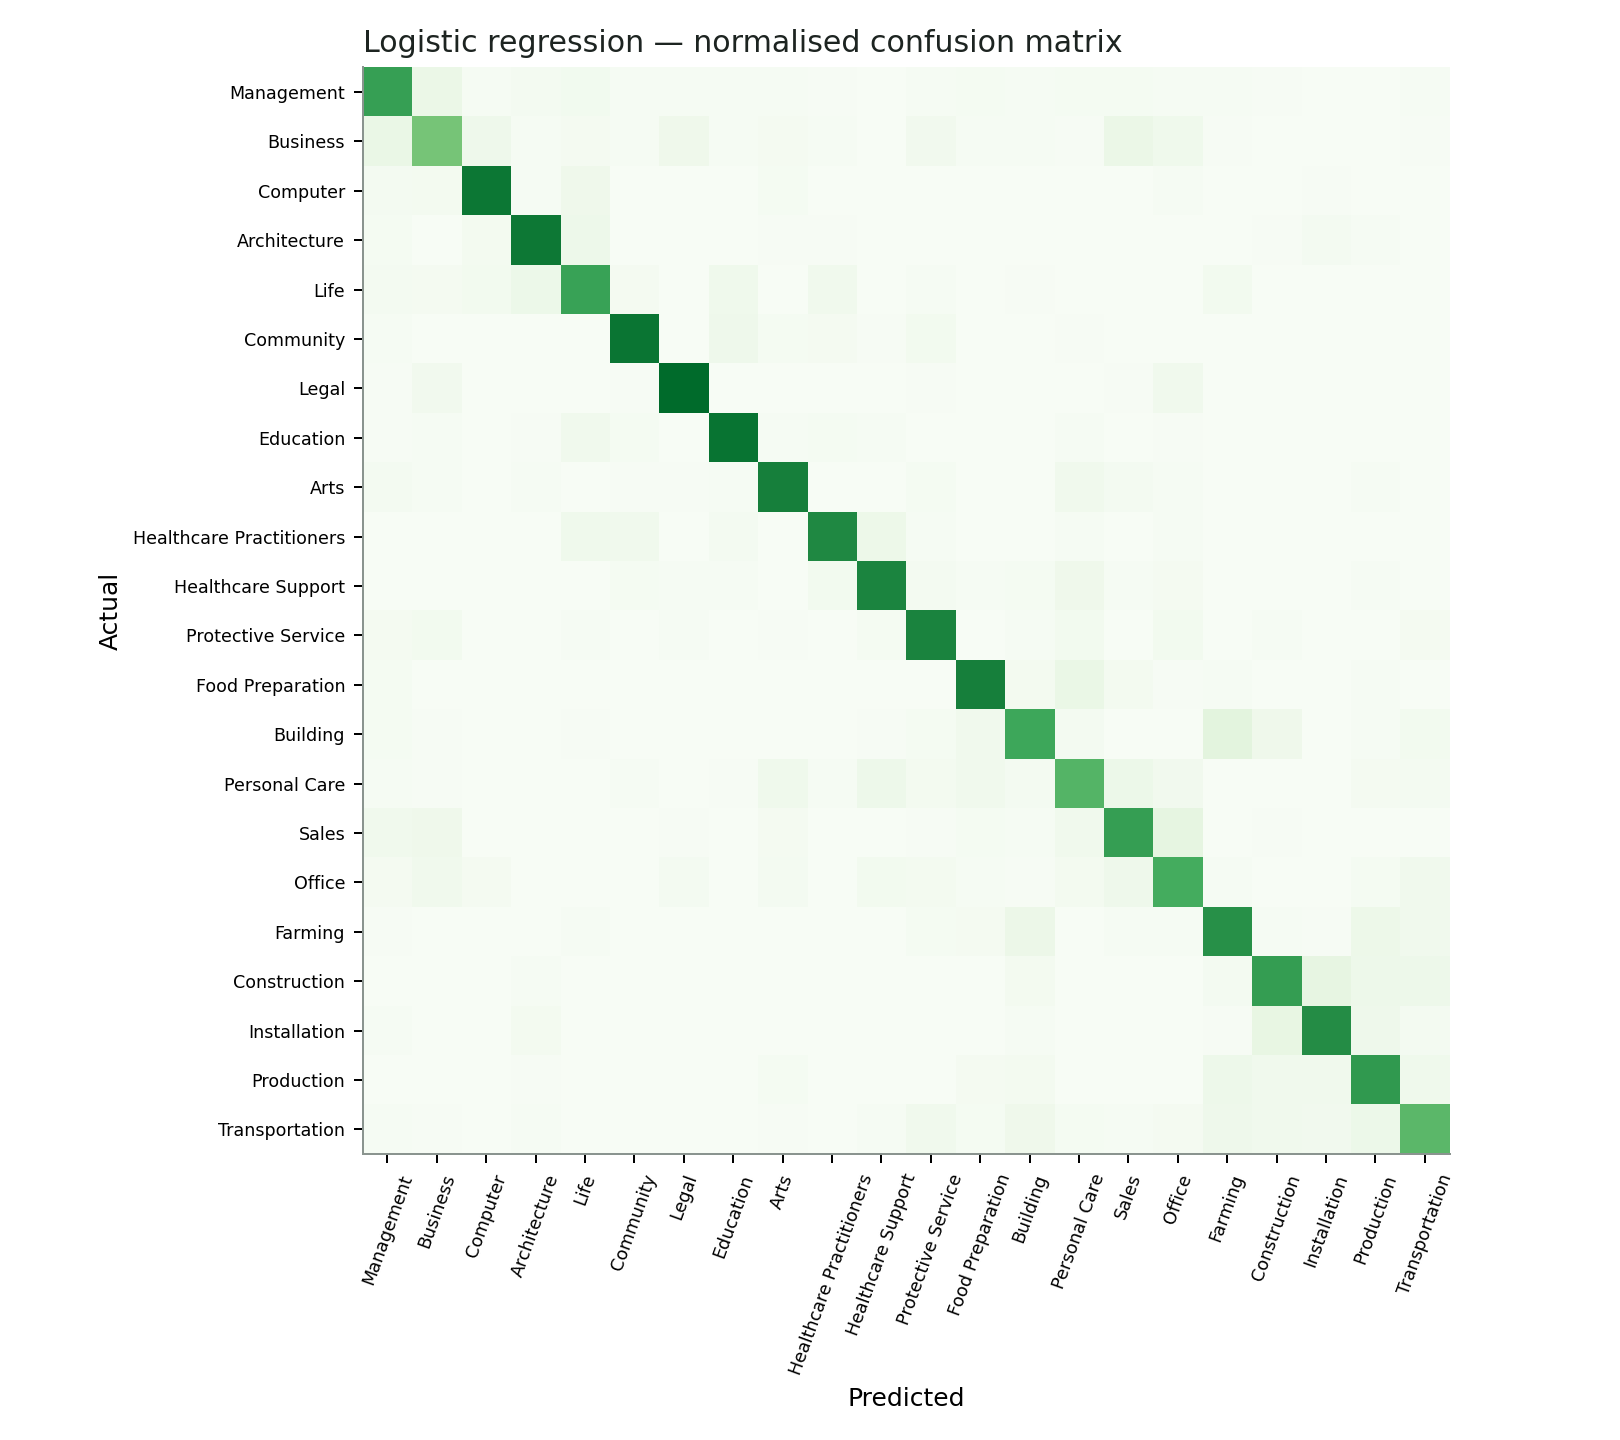

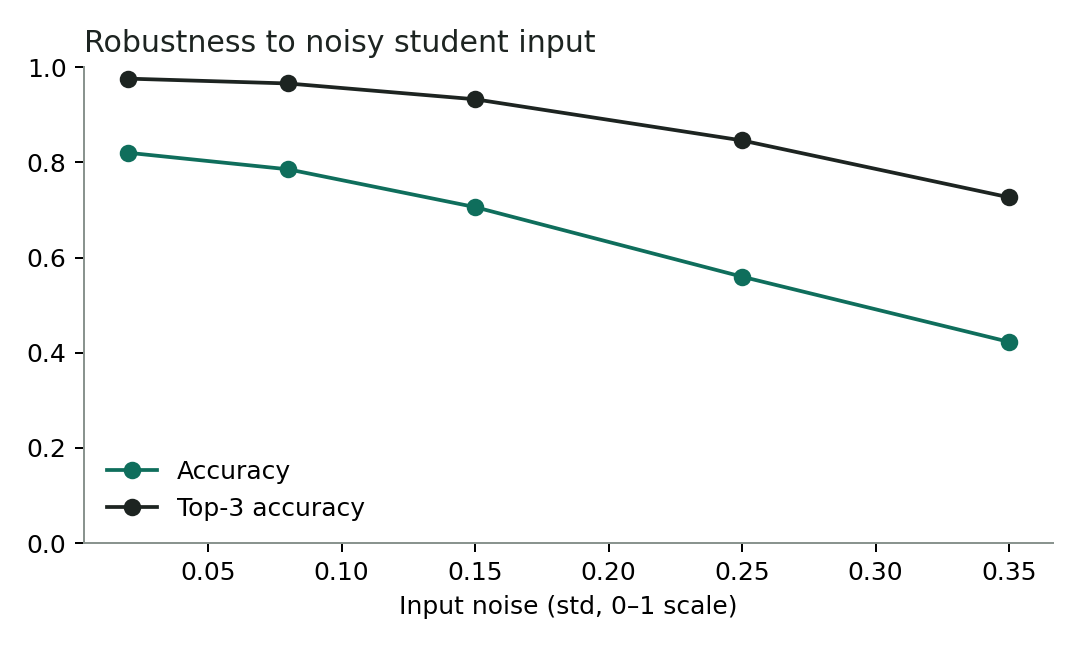

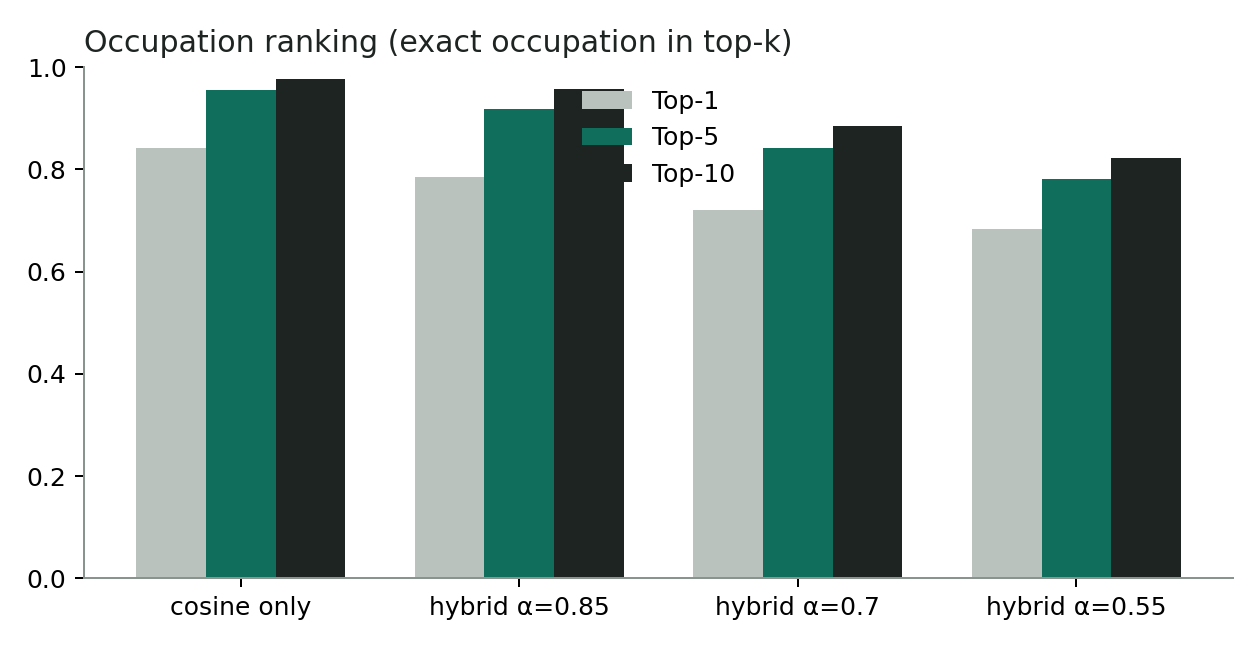

In [6]:
from IPython.display import Image, display
for f in ["model_comparison.png", "confusion_matrix.png", "robustness.png", "ranking.png"]:
    display(Image(filename=str(ROOT / "ml/reports" / f), width=640))

In [7]:
pd.DataFrame(m["C_robustness"]).set_index("noise").round(3)

,accuracy,macro_f1,top3_accuracy
noise,,,
0.02,0.820,0.802,0.976
0.08,0.785,0.758,0.966
0.15,0.706,0.668,0.933
0.25,0.560,0.518,0.846
0.35,0.423,0.384,0.727


In [8]:
pd.DataFrame(m["D_ranking"]).T.round(3)

,top1,top5,top10
cosine only,0.842,0.956,0.978
hybrid α=0.85,0.785,0.918,0.957
hybrid α=0.7,0.721,0.842,0.885
hybrid α=0.55,0.684,0.780,0.822


**Ranking.** Exact-occupation retrieval works best with z-scored cosine similarity alone (top-5 ≈ 0.96); mixing in family
probabilities lowered top-k, so α = 1.0 was selected automatically. Temperature scaling found T = 1.0 optimal on held-out data
(the classifier is already calibrated in-distribution).

## 4. The deployed model in action
The exported JSON is what the web app runs (in TypeScript). Re-implementing inference here for a hand-built profile:

In [9]:
model = json.loads((ROOT / "web/src/server/ml/model/career-model.json").read_text())
cat = json.loads((ROOT / "data/processed/catalogue.json").read_text())
skill_idx = [i for i, f in enumerate(features) if f[:2] in ("es", "ts", "kn")]
def align(x):
    # Distribution alignment (same as the web app): keep the student's relative skill profile,
    # re-expressed on each feature's occupation-importance scale.
    v = x[skill_idx]; out = x.copy()
    out[skill_idx] = np.clip(np.array(model["zMean"])[skill_idx] + (v - v.mean()) / (v.std() or 1) * np.array(model["zStd"])[skill_idx], 0, 1)
    return out
def infer(sparse, aligned=True):
    x = np.array([sparse.get(f, model["impute"][i]) for i, f in enumerate(features)])
    if aligned: x = align(x)
    xs = (x - np.array(model["scaler"]["mean"])) / np.array(model["scaler"]["scale"])
    logits = np.array(model["logreg"]["coef"]) @ xs + np.array(model["logreg"]["intercept"])
    p = np.exp(logits - logits.max()); p /= p.sum()
    z = (x - np.array(model["zMean"])) / np.array(model["zStd"]); z /= np.linalg.norm(z)
    cos = np.array(model["occupations"]["z"]) @ z
    top = np.argsort(-cos)[:8]
    fams = sorted(zip([f["name"] for f in model["families"]], p), key=lambda t: -t[1])[:3]
    return fams, [(cat[model["occupations"]["codes"][i]]["title"], round(float((cos[i] + 1) * 50))) for i in top]

name = {m["id"]: m["name"] for m in meta}
pick = lambda *names: {i for i, n in name.items() if n in names}
student = {f: 0.15 for f in features if f[:2] in ("es", "ts", "kn")}
student.update({f: 0.85 for f in pick("Programming", "Mathematics", "Computers and Electronics", "Critical Thinking", "Complex Problem Solving", "Systems Analysis")})
student.update({"ri:Investigative": 0.9, "ri:Conventional": 0.6, "ri:Realistic": 0.4, "ri:Social": 0.2, "ri:Artistic": 0.2, "ri:Enterprising": 0.2, "jz:zone": 0.75})
raw_fams, raw = infer(student, aligned=False)
fams, careers = infer(student)
print("Career families (aligned):", [(f, round(float(p), 2)) for f, p in fams])
pd.DataFrame({"without alignment": [c for c, _ in raw], "with alignment": [f"{c} ({m}%)" for c, m in careers]})

Career families (aligned): [('Computer & Mathematical', 0.95), ('Life, Physical & Social Science', 0.04), ('Business & Financial', 0.0)]


,without alignment,with alignment
0,Landscaping and Groundskeeping Workers,Data Scientists (87%)
1,Data Scientists,Statisticians (84%)
2,"Pressers, Textile, Garment, and Related Materials",Biostatisticians (81%)
3,"Packers and Packagers, Hand",Mathematicians (81%)
4,Slaughterers and Meat Packers,Operations Research Analysts (80%)
5,Data Warehousing Specialists,Bioinformatics Technicians (79%)
6,Sewing Machine Operators,Financial Quantitative Analysts (79%)
7,Helpers--Production Workers,Statistical Assistants (78%)


**Finding — distribution shift.** Students rate *proficiency* and are low on most descriptors, while occupation vectors hold
*importance* ratings. A raw low-everywhere profile therefore looks like a low-skill occupation (left column). Re-expressing the
student's relative profile on the occupation scale (z-score across their own ratings, then map with each feature's mean/std) fixes
the shift (right column). The web app applies this alignment before every prediction.

## 5. Where this sits in the agent
1. **Profile Analyst** (Groq LLM) rates the student 0–5 on the 68 skill/knowledge descriptors from their CV / profile.
2. RIASEC scores come from a 12-item interest quiz; job zone from education.
3. A distribution-alignment step maps self-rated proficiency onto O*NET's importance scale.
4. **This model** returns career families and ranked occupations.
5. The **Gap Analyzer** compares the student with the target occupation's O*NET *level* requirements; the **Curriculum Planner** and
   **Roadmap Composer** (LLMs) turn the gaps into courses, skills and projects; the **Critic** checks coverage and feasibility.